
# Experiment 02 — Model Capacity Analysis

## Research Question

How does the model capacity affect training loss,
validation performance, and training time
of a NumPy-based MLP trained on MNIST?

## Experimental Setup

| Hyperparameter | Value |
|---|---|
| Architecture | 784 → 64 (ReLU) → 10 (Softmax), 784 → 128 (ReLU) → 10 (Softmax), 784 → 256 (ReLU) → 10 (Softmax) |
| Optimizer | Mini-batch SGD |
| Epochs | 50 |
| Batch size | 64 |
| Seed | 42 |
| Training samples | 55,000 |
| Validation samples | 5,000 |
| Learning rates |0.01|

Only the model capacity is varied across experiments.

## Initial Hypotheses

- H1: Biggest model (784 -> 256 (ReLU) -> 10 (Softmax)) achieves lowest training loss.
- H2: When the capacity of the model gets bigger, the validation performance gets better.
- H3: Bigger models have longer training times compared to smaller ones.


In [1]:
import json
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

EXPERIMENTS_DIR = Path("../experiments/model_capacity")

assert EXPERIMENTS_DIR.exists(), (
    f"Directory not found: {EXPERIMENTS_DIR.resolve()}"
)

In [2]:
experiment_dirs = sorted(
    path for path in EXPERIMENTS_DIR.iterdir()
    if path.is_dir()
)

experiments = []

for experiment_dir in experiment_dirs:
    with open(experiment_dir / "config.json", encoding="utf-8") as f:
        config = json.load(f)

    with open(experiment_dir / "metrics.json", encoding="utf-8") as f:
        metrics = json.load(f)

    with open(experiment_dir / "history.json", encoding="utf-8") as f:
        history = json.load(f)

    experiments.append({
        "name": experiment_dir.name,
        "config": config,
        "metrics": metrics,
        "history": history,
    })

experiments.sort(key=lambda exp: exp["config"]["hidden_dim"])

print(f"Loaded {len(experiments)} experiments.")

for exp in experiments:
    print(exp["name"], "→", exp["config"]["hidden_dim"], "neurons")

Loaded 3 experiments.
mlp_lr0.01_seed42_20261116_103653_070233 → 64 neurons
mlp_lr0.01_seed42_20261116_103851_226925 → 128 neurons
mlp_lr0.01_seed42_20261116_104238_342778 → 256 neurons


In [3]:
assert len(experiments) == 3

assert {exp["config"]["hidden_dim"] for exp in experiments} == {
    64, 128, 256
}

for exp in experiments:
    config = exp["config"]

    assert config["model"] == "mlp"
    assert np.isclose(config["learning_rate"], 0.01)
    assert config["epochs"] == 50
    assert config["batch_size"] == 64
    assert config["seed"] == 42
    assert config["validation_size"] == 5000

    assert len(exp["history"]["train_loss"]) == 50
    assert len(exp["history"]["val_loss"]) == 50

print("Experimental conditions verified.")

Experimental conditions verified.


In [4]:
rows = []

for exp in experiments:
    config = exp["config"]
    metrics = exp["metrics"]
    history = exp["history"]

    h = config["hidden_dim"]

    rows.append({
        "Hidden Dim": h,
        "Parameters": 795 * h + 10,
        "Training Loss": metrics["final_training_loss"],
        "Validation Loss": metrics["validation_loss"],
        "Validation Accuracy (%)": metrics["validation_accuracy"] * 100,
        "Best Val. Epoch": int(np.argmin(history["val_loss"]) + 1),
        "Training Time (s)": metrics["training_time_seconds"],
    })

results_df = pd.DataFrame(rows).sort_values("Hidden Dim")

display(results_df.round(4))

,Hidden Dim,Parameters,Training Loss,Validation Loss,Validation Accuracy (%),Best Val. Epoch,Training Time (s)
0,64,50890,0.1062,0.1369,96.22,50,44.6261
1,128,101770,0.0886,0.1186,96.72,50,73.9888
2,256,203530,0.0825,0.1125,96.96,50,175.9934



## Training Loss Comparison

This section examines how increasing model capacity affects
the optimization process and the ability of the network
to fit the training data.

We compare the training loss curves of MLPs with 64, 128,
and 256 hidden neurons under the same training protocol.


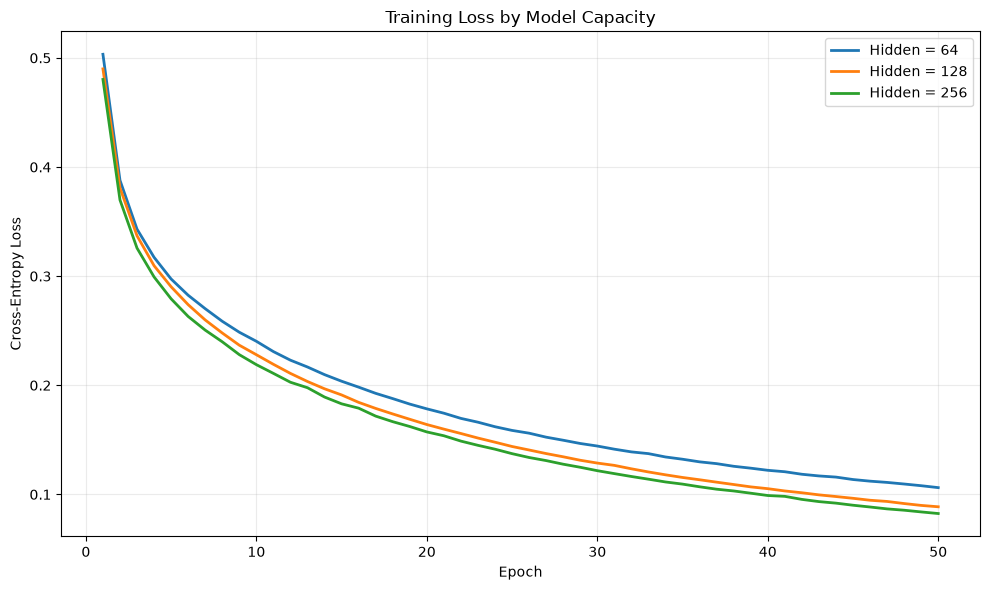

In [5]:
fig, ax = plt.subplots(figsize=(10, 6))

for exp in experiments:
    h = exp["config"]["hidden_dim"]
    losses = exp["history"]["train_loss"]
    epochs = np.arange(1, len(losses) + 1)

    ax.plot(epochs, losses, label=f"Hidden = {h}", linewidth=2)

ax.set(
    title="Training Loss by Model Capacity",
    xlabel="Epoch",
    ylabel="Cross-Entropy Loss",
)

ax.grid(alpha=0.25)
ax.legend()
fig.tight_layout()
plt.show()


## Validation Loss Comparison

Validation loss measures how well each model performs
on data not used for parameter optimization.

By comparing validation loss curves, we investigate
whether increasing model capacity improves generalization
and whether the additional parameters provide meaningful
benefits beyond training performance.


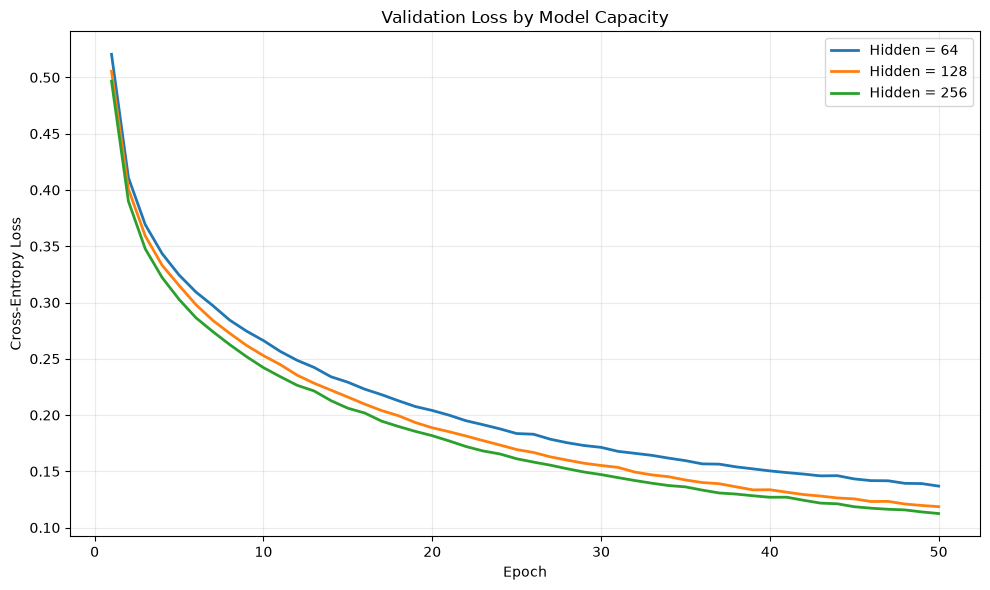

In [6]:
fig, ax = plt.subplots(figsize=(10, 6))

for exp in experiments:
    h = exp["config"]["hidden_dim"]
    losses = exp["history"]["val_loss"]
    epochs = np.arange(1, len(losses) + 1)

    ax.plot(epochs, losses, label=f"Hidden = {h}", linewidth=2)

ax.set(
    title="Validation Loss by Model Capacity",
    xlabel="Epoch",
    ylabel="Cross-Entropy Loss",
)

ax.grid(alpha=0.25)
ax.legend()
fig.tight_layout()
plt.show()


## Model Capacity and Validation Accuracy

Increasing the hidden layer size increases the number
of trainable parameters.

This comparison examines whether additional model
capacity translates into improved validation accuracy,
and whether the observed gains justify the increased
model complexity.


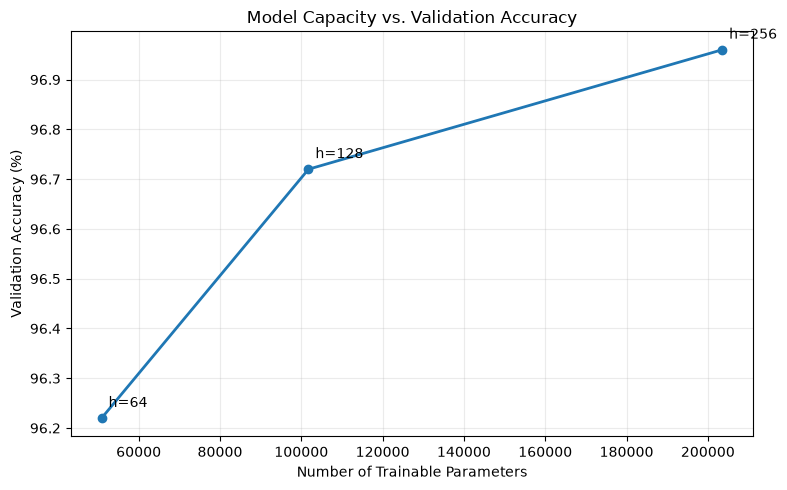

In [7]:
fig, ax = plt.subplots(figsize=(8, 5))

ax.plot(
    results_df["Parameters"],
    results_df["Validation Accuracy (%)"],
    marker="o",
    linewidth=2,
)

for _, row in results_df.iterrows():
    ax.annotate(
        f'h={int(row["Hidden Dim"])}',
        (
            row["Parameters"],
            row["Validation Accuracy (%)"],
        ),
        xytext=(5, 8),
        textcoords="offset points",
    )

ax.set(
    title="Model Capacity vs. Validation Accuracy",
    xlabel="Number of Trainable Parameters",
    ylabel="Validation Accuracy (%)",
)

ax.grid(alpha=0.25)
fig.tight_layout()
plt.show()


## Generalization Gap

The generalization gap is the difference between
validation loss and training loss:

$$
\text{Generalization Gap}
=
L_{\text{validation}} - L_{\text{training}}
$$

This comparison investigates whether increasing model
capacity leads to larger differences between training
and validation performance.

A larger gap may suggest that a model fits the training
data more closely, but does not necessarily indicate
overfitting on its own.


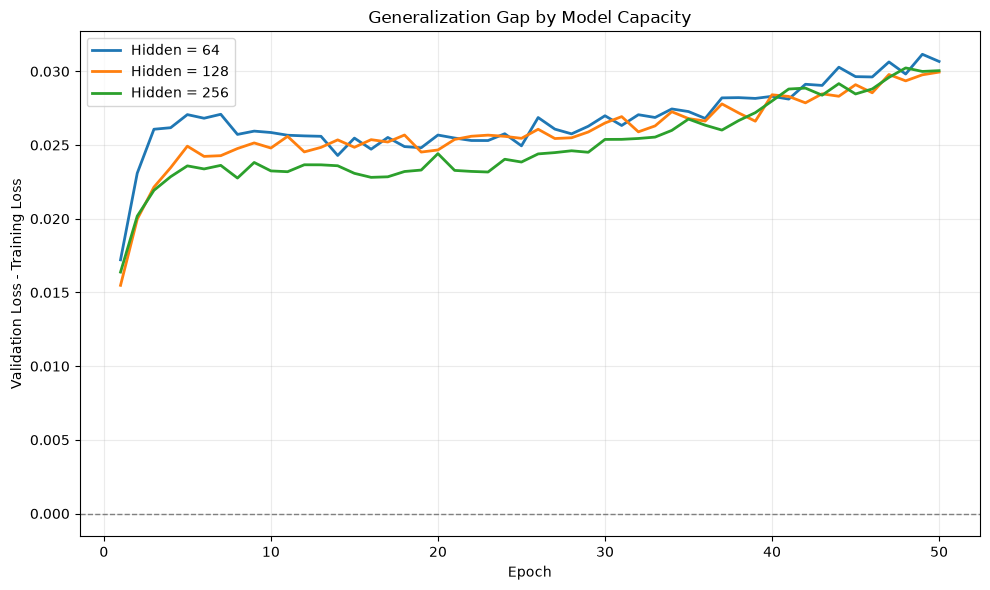

In [8]:
fig, ax = plt.subplots(figsize=(10, 6))

for exp in experiments:
    h = exp["config"]["hidden_dim"]

    train_loss = np.asarray(exp["history"]["train_loss"])
    val_loss = np.asarray(exp["history"]["val_loss"])

    gap = val_loss - train_loss

    ax.plot(
        np.arange(1, len(gap) + 1),
        gap,
        label=f"Hidden = {h}",
        linewidth=2,
    )

ax.axhline(0, color="gray", linestyle="--", linewidth=1)

ax.set(
    title="Generalization Gap by Model Capacity",
    xlabel="Epoch",
    ylabel="Validation Loss - Training Loss",
)

ax.grid(alpha=0.25)
ax.legend()
fig.tight_layout()
plt.show()

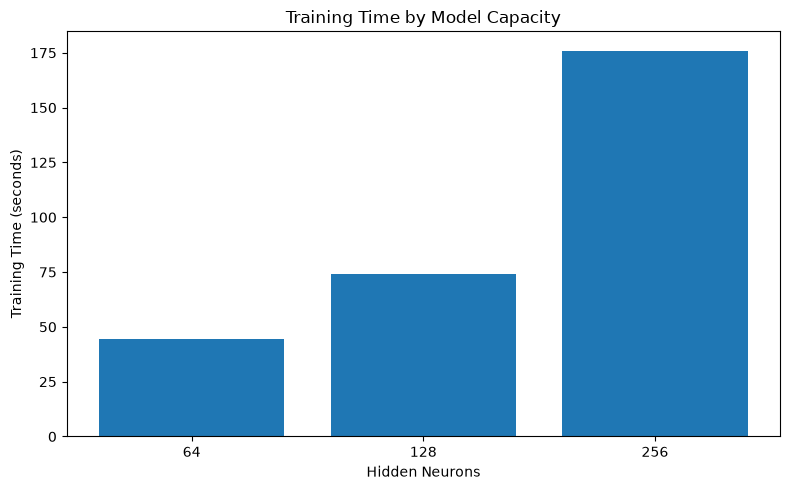

In [9]:
fig, ax = plt.subplots(figsize=(8, 5))

ax.bar(
    results_df["Hidden Dim"].astype(str),
    results_df["Training Time (s)"],
)

ax.set(
    title="Training Time by Model Capacity",
    xlabel="Hidden Neurons",
    ylabel="Training Time (seconds)",
)

fig.tight_layout()
plt.show()

## Results and Discussion

### 1. Training Performance

Increasing the hidden layer size consistently reduced training loss. The model with 256 hidden neurons achieved the lowest final training loss (0.0825), supporting the hypothesis that greater model capacity can improve the network's ability to fit the training data.

### 2. Validation Performance

Validation accuracy increased from 96.22% with 64 hidden neurons to 96.72% with 128 and 96.96% with 256 neurons.

However, the improvement became smaller as model capacity increased. Doubling the hidden layer size from 64 to 128 improved accuracy by 0.50 percentage points, while doubling it again improved accuracy by only 0.24 percentage points.

This suggests diminishing performance gains within the tested configurations.

### 3. Generalization

Despite the differences in model capacity, all three models achieved similar final generalization gaps of approximately 0.03.

Increasing the number of hidden neurons improved both training and validation performance without producing a substantial increase in the final generalization gap.

Therefore, the experiments do not provide clear evidence that increasing model capacity caused additional overfitting.

### 4. Computational Cost

Larger models required more trainable parameters and longer training times.

Increasing the hidden layer size from 128 to 256 approximately doubled the parameter count, while measured training time increased from 74 to 176 seconds.

Although the 256-neuron model achieved the highest validation accuracy, the 128-neuron model may offer a more favorable trade-off between model complexity and predictive performance.

### 5. Hypothesis Evaluation

All three initial hypotheses were supported by the observations:

- **H1:** The largest model achieved the lowest training loss.
- **H2:** Validation performance improved with increasing capacity, although the gains diminished.
- **H3:** Larger models required more parameters and longer training times.

These findings apply to the tested configurations and do not establish that increasing model capacity always improves performance.

### 6. Limitations

The experiments used a single random seed and a fixed training protocol of 50 epochs.

Different architectures may require different optimization settings, and the observed results do not guarantee that each model reached its optimal performance.

Training time was measured using a single execution per configuration and may be affected by system-level factors.